# NACA5D_10 - NACA4D_10: Aerodynamic Coefficient Prediction

## Setup and Configuration

In [1]:
# Set TensorFlow logging and numerical options
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "1"

In [2]:
# Load the libraries and configure the experiment
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from keras import Input, Sequential, backend, utils
from keras.callbacks import ReduceLROnPlateau
from keras.layers import Dense
from keras.metrics import RootMeanSquaredError
from keras.optimizers import Adam
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

ROOT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "results").is_dir() and (p / "notebooks").is_dir()
)
N_RUNS = 20
EPOCHS = 50
TARGETS = ["CL", "CD", "Cm"]
SOURCE_FAMILY = "NACA5D_10"
TEST_FAMILY = "NACA4D_10"
ARCHITECTURES = ["M_512_256_128"]


sys.path.insert(0, str(ROOT / "notebooks"))
experiment_results = __import__("experiment_results")
figure_output = __import__("figure_output")


def dataset_path(name):
    return experiment_results.dataset_path(ROOT, name)

In [3]:
# Format coefficient tables consistently
def style_table(table):
    return table.style.set_table_styles(
        [
            {"selector": "th", "props": [("text-align", "left")]},
            {"selector": "td", "props": [("text-align", "left")]},
        ]
    ).format(precision=6)


def show_table(table):
    display(style_table(table))


def model_index(names, case_numbers=None):
    numbers = (
        range(1, len(names) + 1)
        if case_numbers is None
        else [case_numbers[name] for name in names]
    )
    return pd.MultiIndex.from_tuples(
        [(number, architecture(name)) for number, name in zip(numbers, names)],
        names=["Case No.", "Network Architecture"],
    )


def metric_table(names, records, measures, case_numbers=None):
    columns = [f"{target}_{key}" for key, label in measures for target in TARGETS]
    table = pd.DataFrame([records[name].mean()[columns].to_numpy() for name in names])
    table.index = model_index(names, case_numbers)
    table.columns = pd.MultiIndex.from_tuples(
        [(label, target) for key, label in measures for target in TARGETS]
    )
    return table

In [4]:
# Style, save, and display the figures
plt.style.use("default")
plt.rcParams.update(
    {
        "figure.dpi": 160,
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 9,
        "legend.frameon": False,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "0.35",
        "axes.linewidth": 0.7,
        "axes.axisbelow": True,
        "axes.formatter.use_mathtext": True,
        "grid.color": "0.88",
        "grid.linewidth": 0.6,
        "lines.linewidth": 1.6,
        "figure.constrained_layout.use": True,
    }
)
BLUE, ORANGE, GREEN = "#0072B2", "#D55E00", "#009E73"
NOTEBOOK_NAME = "NACA5D_10 - NACA4D_10"
FIGURES = ROOT / "images" / NOTEBOOK_NAME
FIGURES.mkdir(parents=True, exist_ok=True)


def architecture(name):
    return "(" + name.removeprefix("M_").replace("_", "-") + "-3)"


def finish_figure(fig, filename, table=None, caption=None):
    figure_output.finish_figure(
        fig,
        FIGURES,
        filename,
        table=style_table(table) if table is not None else None,
        caption=caption,
    )


def plot_learning_curve(name, section, limits):
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    for key, color, ls, label in [
        ("loss", "#332288", "-", "Training"),
        ("val_loss", "#CC6677", "--", "Validation"),
    ]:
        values = np.asarray([run[key] for run in histories[name]])
        epochs = np.arange(1, values.shape[1] + 1)
        ax.plot(
            epochs,
            np.median(values, axis=0),
            color=color,
            linestyle=ls,
            marker="D",
            markersize=2.5,
            markevery=np.flatnonzero(epochs % 10 == 0).tolist(),
            label=label,
        )
        if len(values) > 1:
            lo, hi = np.percentile(values, [10, 90], axis=0)
            ax.fill_between(epochs, lo, hi, color=color, alpha=0.12, linewidth=0)
    ax.set(
        xlabel="Epoch",
        ylabel="Mean squared error (MSE)",
        yscale="log",
    )
    ax.set_ylim(limits)
    last_epoch = max(len(run["loss"]) for runs in histories.values() for run in runs)
    last_tick = int(np.ceil(last_epoch / 10)) * 10
    ax.set_xlim(0, last_tick + 1)
    ax.set_xticks(np.arange(0, last_tick + 1, 10))
    ax.grid(axis="both", which="major", color="0.88", linewidth=0.6)
    ax.set_title(f"Architecture {architecture(name)}")
    ax.legend(loc="upper right")
    means = metrics[name].mean()
    table = pd.DataFrame(
        [[means[f"{target}_{key}"] for target in TARGETS] for key in ["rmse", "r2"]],
        index=pd.Index(["RMSE", "R²"], name="Metric"),
        columns=TARGETS,
    )
    layers = name.removeprefix("M_").replace("_", "-")
    finish_figure(
        fig,
        f"{section}-{layers}-mse",
        table=table,
        caption=f"Architecture {architecture(name)}. Mean squared error (MSE) is the "
        "squared prediction error averaged over samples and the three outputs "
        "(CL, CD, Cm), with equal weight for each output. Targets are unscaled; "
        "no target normalisation is applied. Curves show the median and "
        f"10–90% range across {N_RUNS} independent training runs (random seeds).",
    )


def learning_curve_limits():
    loss_values = np.concatenate(
        [
            np.asarray(run[key]).ravel()
            for runs in histories.values()
            for run in runs
            for key in ["loss", "val_loss"]
        ]
    )
    positive_losses = loss_values[np.isfinite(loss_values) & (loss_values > 0)]
    if not len(positive_losses):
        raise ValueError("Learning curves require positive finite losses")
    loss_limits = (
        10 ** np.floor(np.log10(positive_losses.min())),
        10 ** np.ceil(np.log10(positive_losses.max())),
    )
    if loss_limits[0] == loss_limits[1]:
        loss_limits = (loss_limits[0] / 10, loss_limits[1] * 10)
    return loss_limits


def show_learning_curve(name, section, limits=None):
    from IPython.utils.capture import capture_output

    if limits is None:
        limits = learning_curve_limits()
    with capture_output() as curve_output:
        plot_learning_curve(name, section, limits)
    content = HTML("".join(output.data["text/html"] for output in curve_output.outputs))
    key = (section, name)
    if key in learning_curve_displays:
        learning_curve_displays[key].update(content)
    else:
        learning_curve_displays[key] = display(content, display_id=True)

In [5]:
# Train seeded models and evaluate coefficient errors
learning_curve_displays = {}
histories = {}
models = {}
metrics = {}
validation_metrics = {}
test_predictions = {}


def make_reduce_lr():
    return ReduceLROnPlateau(monitor="val_loss", factor=0.9, patience=5, min_lr=0.00001)


def coefficient_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted, multioutput="raw_values")
    r2 = r2_score(actual, predicted, multioutput="raw_values")
    return {
        **{f"{target}_mse": mse[j] for j, target in enumerate(TARGETS)},
        **{f"{target}_rmse": np.sqrt(mse[j]) for j, target in enumerate(TARGETS)},
        **{f"{target}_r2": r2[j] for j, target in enumerate(TARGETS)},
    }


def train_architecture(name):
    if name in metrics:
        return
    hidden_layers = [int(size) for size in name.removeprefix("M_").split("_")]
    histories[name] = []
    run_metrics = []
    run_validation = []
    for i in range(N_RUNS):
        backend.clear_session()
        utils.set_random_seed(42 + i)
        print(f"Run {i + 1}/{N_RUNS} for model {architecture(name)}")
        model = Sequential(
            [Input(shape=(X_train.shape[1],))]
            + [Dense(size, activation="relu") for size in hidden_layers]
            + [Dense(len(TARGETS), activation="linear")]
        )
        model.compile(
            optimizer=Adam(learning_rate=5e-4, beta_1=0.9, beta_2=0.999),
            loss="mse",
            metrics=[RootMeanSquaredError()],
        )
        history = model.fit(
            X_train,
            y_train,
            epochs=EPOCHS,
            batch_size=128,
            validation_data=(X_val, y_val),
            callbacks=[make_reduce_lr()],
            verbose=0,
        )
        histories[name].append(history.history)
        predictions = model.predict(X_test, verbose=0)
        run_metrics.append(coefficient_metrics(y_test, predictions))
        run_validation.append(
            coefficient_metrics(y_val, model.predict(X_val, verbose=0))
        )
        if i == 0:
            models[name] = model
            test_predictions[name] = predictions
    metrics[name] = pd.DataFrame(run_metrics)
    validation_metrics[name] = pd.DataFrame(run_validation)

## Dataset Inspection

In [6]:
# Load and inspect both airfoil families
DATASETS = experiment_results.dataset_manifest(ROOT, ["NACA4D_10", "NACA5D_10"])
df4 = pd.read_csv(dataset_path("NACA4D_10"))
df5 = pd.read_csv(dataset_path("NACA5D_10"))
for frame in [df4, df5]:
    show_table(frame.head(10))
    show_table(frame.isnull().sum().to_frame("Missing Values"))
    show_table(frame.describe())

,t,m,p,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re,CL,CD,Cm
0,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-10.000000,0.200000,100000,-1.158000,0.026570,0.005000
1,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-9.000000,0.200000,100000,-1.043000,0.021940,0.004000
2,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-8.000000,0.200000,100000,-0.928000,0.018760,0.004000
3,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-7.000000,0.200000,100000,-0.813000,0.014630,0.004000
4,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-6.000000,0.200000,100000,-0.697000,0.028060,0.003000
5,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-5.000000,0.200000,100000,-0.581000,0.016600,0.003000
6,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-4.000000,0.200000,100000,-0.465000,0.011460,0.002000
7,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-3.000000,0.200000,100000,-0.349000,0.008930,0.002000
8,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-2.000000,0.200000,100000,-0.233000,0.013930,0.001000
9,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-1.000000,0.200000,100000,-0.116000,0.013580,0.001000


,Missing Values
t,0
m,0
p,0
yU1,0
yU2,0
yU3,0
yU4,0
yU5,0
yU6,0
yU7,0


,t,m,p,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re,CL,CD,Cm
count,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000
mean,20.000000,4.500000,40.000000,0.056883,0.096159,0.125194,0.138691,0.136083,0.120107,0.094865,0.064420,0.033738,0.010667,-0.022655,-0.044818,-0.059290,-0.061519,-0.053798,-0.040218,-0.025367,-0.013472,-0.006526,-0.003090,0.000000,0.200000,300000.000000,0.692283,0.026646,-0.134151
std,10.000028,2.872289,22.912943,0.030652,0.043042,0.052297,0.056240,0.054535,0.048225,0.039002,0.028046,0.015531,0.004912,0.018877,0.038948,0.050931,0.056142,0.054327,0.047521,0.037872,0.026573,0.014169,0.004346,6.055318,0.081650,141421.757093,0.926925,0.010960,0.113007
min,5.000000,0.000000,5.000000,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.068776,-0.125166,-0.161693,-0.174931,-0.165684,-0.139753,-0.104640,-0.067474,-0.034638,-0.011856,-10.000000,0.100000,100000.000000,-1.489000,0.001800,-0.514000
25%,10.000000,2.000000,22.500000,0.031423,0.060652,0.084089,0.094866,0.094677,0.083039,0.065317,0.043257,0.022149,0.006859,-0.035908,-0.073796,-0.098240,-0.105515,-0.094677,-0.076403,-0.053389,-0.032844,-0.016811,-0.006339,-5.000000,0.100000,200000.000000,-0.011000,0.018990,-0.199000
50%,20.000000,4.500000,40.000000,0.054270,0.096111,0.124907,0.138240,0.136379,0.119788,0.094447,0.063249,0.032542,0.010311,-0.020812,-0.044485,-0.059570,-0.062106,-0.053219,-0.039929,-0.025009,-0.014037,-0.006982,-0.003241,-0.000000,0.200000,300000.000000,0.691000,0.025390,-0.106000
75%,30.000000,7.000000,57.500000,0.078524,0.129458,0.166614,0.182079,0.176607,0.156303,0.123175,0.083105,0.043066,0.013765,-0.008222,-0.016155,-0.019867,-0.018542,-0.013697,-0.004779,0.001474,0.004181,0.002635,-0.000235,5.000000,0.300000,400000.000000,1.379000,0.032540,-0.046000
max,35.000000,9.000000,75.000000,0.149810,0.208025,0.246146,0.264431,0.256034,0.230429,0.194578,0.153941,0.091494,0.029468,0.034685,0.072121,0.066841,0.064704,0.066036,0.069760,0.074748,0.071348,0.042540,0.011816,10.000000,0.300000,500000.000000,3.599000,0.235470,0.025000


,t,CL_design,p,s,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re,CL,CD,Cm
0,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-10.000000,0.100000,100000,-1.140000,0.024940,0.005000
1,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-9.000000,0.100000,100000,-1.027000,0.021160,0.004000
2,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-8.000000,0.100000,100000,-0.914000,0.016970,0.004000
3,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-7.000000,0.100000,100000,-0.800000,0.013640,0.003000
4,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-6.000000,0.100000,100000,-0.687000,0.024830,0.003000
5,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-5.000000,0.100000,100000,-0.572000,0.015650,0.002000
6,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-4.000000,0.100000,100000,-0.458000,0.011140,0.002000
7,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-3.000000,0.100000,100000,-0.344000,0.008820,0.001000
8,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-2.000000,0.100000,100000,-0.229000,0.013910,0.001000
9,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-1.000000,0.100000,100000,-0.115000,0.013570,0.000000


,Missing Values
t,0
CL_design,0
p,0
s,0
yU1,0
yU2,0
yU3,0
yU4,0
yU5,0
yU6,0


,t,CL_design,p,s,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re,CL,CD,Cm
count,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000
mean,19.964508,0.841171,27.648625,0.493345,0.061993,0.102135,0.127800,0.134156,0.122524,0.098694,0.069992,0.042583,0.020752,0.006938,-0.018404,-0.038130,-0.055586,-0.065870,-0.068018,-0.062462,-0.050760,-0.035252,-0.019158,-0.006666,0.000000,0.200000,300000.000000,0.219104,0.025913,0.008665
std,10.002176,0.595675,16.859596,0.499957,0.035497,0.050154,0.062040,0.067278,0.064190,0.054114,0.040238,0.025606,0.012848,0.004050,0.023772,0.045955,0.061393,0.066364,0.061834,0.051451,0.038246,0.024719,0.012716,0.004107,6.055314,0.081686,141421.655012,0.926011,0.011283,0.092562
min,5.000000,0.000000,5.000000,0.000000,0.002846,-0.006454,-0.022993,-0.039093,-0.048037,-0.046811,-0.048429,-0.042975,-0.025120,-0.006870,-0.099508,-0.159542,-0.203795,-0.225166,-0.220449,-0.192701,-0.171128,-0.127512,-0.072044,-0.023250,-10.000000,0.100000,100000.000000,-2.607000,0.002690,-0.169000
25%,10.000000,0.200000,15.000000,0.000000,0.033635,0.064809,0.081379,0.082846,0.074521,0.059894,0.041483,0.024170,0.011355,0.003817,-0.031207,-0.071458,-0.101465,-0.116798,-0.116477,-0.099824,-0.078123,-0.052613,-0.027989,-0.009654,-5.000000,0.100000,200000.000000,-0.485000,0.018260,-0.031000
50%,20.000000,0.800000,25.000000,0.000000,0.057851,0.101474,0.127721,0.133115,0.120174,0.099175,0.069387,0.042334,0.020455,0.006776,-0.011933,-0.034474,-0.055389,-0.067278,-0.069486,-0.061501,-0.050658,-0.034769,-0.018871,-0.006613,-0.000000,0.200000,300000.000000,0.218000,0.024650,-0.004000
75%,30.000000,1.400000,45.000000,1.000000,0.085249,0.134294,0.169672,0.179965,0.165684,0.137987,0.098800,0.061646,0.030411,0.010163,-0.001288,-0.008175,-0.014868,-0.021079,-0.023669,-0.023748,-0.022239,-0.016698,-0.009816,-0.003398,5.000000,0.300000,400000.000000,0.928000,0.031580,0.018000
max,35.000000,1.800000,75.000000,1.000000,0.165549,0.250220,0.311403,0.334353,0.308679,0.262679,0.188556,0.108223,0.053854,0.016816,0.045169,0.080046,0.123952,0.132533,0.111633,0.085495,0.048283,0.022775,0.009953,0.002097,10.000000,0.300000,500000.000000,3.020000,0.617020,0.453000


In [7]:
# Remove family-specific geometry parameters
df4 = df4.drop(columns=["t", "m", "p"])
df5 = df5.drop(columns=["t", "CL_design", "p", "s"])

# Shuffle each family and separate features from targets
df4 = df4.sample(frac=1, random_state=42)
df5 = df5.sample(frac=1, random_state=42)
X4, y4 = df4.drop(columns=TARGETS), df4[TARGETS]
X5, y5 = df5.drop(columns=TARGETS), df5[TARGETS]
for features, targets in [(X4, y4), (X5, y5)]:
    show_table(features.head(10))
    show_table(targets.head(10))

,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re
3725,0.049125,0.089404,0.115495,0.124951,0.118346,0.099824,0.074743,0.048196,0.024741,0.008469,-0.049125,-0.089404,-0.115495,-0.124951,-0.118346,-0.099824,-0.074743,-0.048196,-0.024741,-0.008469,-2.000000,0.300000,300000
59666,0.013694,0.030280,0.045517,0.054151,0.053220,0.046507,0.035900,0.023494,0.011857,0.003541,-0.006235,-0.005772,-0.000860,0.004158,0.005880,0.006559,0.005969,0.004175,0.001933,0.000146,-5.000000,0.200000,200000
88922,0.073693,0.101409,0.117753,0.121857,0.113714,0.095821,0.071836,0.046196,0.023277,0.007309,0.000103,-0.001542,-0.019433,-0.028099,-0.028930,-0.024853,-0.018653,-0.012236,-0.006716,-0.002912,-2.000000,0.300000,500000
77857,0.038665,0.072618,0.100166,0.113865,0.110480,0.095562,0.073190,0.047807,0.024320,0.007623,-0.021325,-0.035729,-0.039242,-0.036146,-0.031572,-0.024358,-0.016702,-0.010254,-0.005502,-0.002555,-0.000000,0.100000,300000
92236,0.100345,0.154953,0.186399,0.198529,0.188323,0.160315,0.121193,0.078629,0.040069,0.012946,-0.010098,-0.046416,-0.086530,-0.101188,-0.097414,-0.081623,-0.060377,-0.038682,-0.020112,-0.007468,-6.000000,0.300000,300000
130715,0.031731,0.066981,0.099575,0.118051,0.116353,0.102123,0.079172,0.052013,0.026272,0.007768,-0.009895,-0.007395,0.005366,0.017950,0.021629,0.022016,0.018973,0.012978,0.006161,0.000890,1.000000,0.200000,500000
116157,0.068406,0.117657,0.156413,0.177901,0.178102,0.157870,0.123488,0.082166,0.042316,0.013261,-0.030971,-0.062765,-0.076293,-0.072853,-0.058795,-0.042156,-0.026771,-0.015317,-0.007902,-0.003806,-4.000000,0.300000,200000
173587,0.069752,0.120291,0.162049,0.188844,0.197433,0.188004,0.163476,0.119165,0.064808,0.019877,-0.030362,-0.061048,-0.072050,-0.063528,-0.040569,-0.011851,0.013927,0.019912,0.011786,0.001509,-9.000000,0.300000,200000
66973,0.033351,0.061767,0.083757,0.095968,0.097435,0.089364,0.074135,0.051596,0.027269,0.008569,-0.026049,-0.045768,-0.055166,-0.054156,-0.044644,-0.030402,-0.015528,-0.006399,-0.002599,-0.001642,-6.000000,0.200000,500000
114055,0.088336,0.144740,0.187627,0.208243,0.201780,0.174940,0.134486,0.088438,0.045336,0.014408,-0.027894,-0.069227,-0.090008,-0.091877,-0.082825,-0.065742,-0.046247,-0.028613,-0.014829,-0.005989,-6.000000,0.100000,200000


,CL,CD,Cm
3725,-0.279000,0.024120,0.004000
59666,-0.228000,0.019660,-0.074000
88922,0.316000,0.008700,-0.058000
77857,0.521000,0.015970,-0.102000
92236,-0.159000,0.027820,-0.062000
130715,0.993000,0.014590,-0.179000
116157,0.414000,0.026430,-0.187000
173587,0.500000,0.030790,-0.389000
66973,-0.216000,0.017230,-0.126000
114055,0.078000,0.028610,-0.140000


,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re
127447,0.072336,0.102507,0.123325,0.127957,0.118225,0.098074,0.072430,0.046144,0.023324,0.007684,-0.001904,-0.031492,-0.058637,-0.071957,-0.072353,-0.063218,-0.048470,-0.031868,-0.016700,-0.005961,9.000000,0.100000,400000
134323,0.096824,0.151324,0.181159,0.181256,0.161784,0.129093,0.091490,0.055989,0.027438,0.009001,-0.003921,-0.017866,-0.046158,-0.069695,-0.077839,-0.073515,-0.060256,-0.041790,-0.022690,-0.008090,-3.000000,0.100000,200000
94858,0.078387,0.129752,0.166295,0.177713,0.161473,0.127457,0.088306,0.052445,0.025021,0.008220,-0.019008,-0.047793,-0.063594,-0.072320,-0.077294,-0.074182,-0.062504,-0.044571,-0.024701,-0.008761,-9.000000,0.100000,300000
161972,0.019856,0.047991,0.074577,0.088858,0.086274,0.070246,0.049382,0.029982,0.014308,0.004081,-0.001404,0.010711,0.027652,0.038847,0.038874,0.030071,0.019283,0.010576,0.004350,0.000677,10.000000,0.300000,300000
106583,0.095721,0.136770,0.181180,0.197080,0.186711,0.157084,0.117200,0.075275,0.038349,0.012830,0.004549,-0.031455,-0.130966,-0.151968,-0.148637,-0.127583,-0.096507,-0.062732,-0.032432,-0.011233,-2.000000,0.100000,100000
106551,0.095721,0.136770,0.181180,0.197080,0.186711,0.157084,0.117200,0.075275,0.038349,0.012830,0.004549,-0.031455,-0.130966,-0.151968,-0.148637,-0.127583,-0.096507,-0.062732,-0.032432,-0.011233,8.000000,0.300000,400000
201425,0.036237,0.090663,0.132826,0.140801,0.119721,0.092169,0.064204,0.038741,0.018339,0.005107,0.008948,0.048351,0.085369,0.090586,0.071710,0.051666,0.033877,0.019189,0.008306,0.001680,4.000000,0.100000,200000
70383,0.095897,0.151840,0.190268,0.203922,0.191028,0.159659,0.118602,0.075954,0.038619,0.012888,-0.035229,-0.092556,-0.131284,-0.145994,-0.141265,-0.120943,-0.091559,-0.059564,-0.030888,-0.010803,2.000000,0.200000,200000
9816,0.039300,0.071524,0.092396,0.099961,0.094677,0.079859,0.059794,0.038557,0.019793,0.006775,-0.039300,-0.071524,-0.092396,-0.099961,-0.094677,-0.079859,-0.059794,-0.038557,-0.019793,-0.006775,-1.000000,0.100000,300000
177205,0.044771,0.099103,0.117614,0.102185,0.079964,0.056239,0.034910,0.018567,0.007908,0.002253,0.013996,0.059077,0.071352,0.051596,0.032084,0.015950,0.004820,-0.000782,-0.002008,-0.001137,-3.000000,0.100000,400000


,CL,CD,Cm
127447,1.455000,0.026270,-0.007000
134323,0.019000,0.017750,0.028000
94858,-0.903000,0.026730,0.028000
161972,1.793000,0.016550,-0.114000
106583,-0.017000,0.020610,0.003000
106551,1.483000,0.040620,-0.010000
201425,1.375000,0.020260,-0.119000
70383,0.629000,0.034080,-0.025000
9816,-0.129000,0.017450,0.002000
177205,0.101000,0.035200,0.001000


## Data Splitting and Feature Scaling

The source family is split by row into 80% training and 20% validation. The test set is the entire target family. The two 10-point datasets share seven exact surface-coordinate profiles.

In [8]:
# Split the source family 80/20 and test on the other family
X_train, X_val, y_train, y_val = train_test_split(
    X5, y5, train_size=0.8, random_state=42
)
X_test, y_test = X4, y4

# Show source split sizes and the target-family test size
split_summary = pd.DataFrame(
    {
        "Samples": [len(X_train), len(X_val), len(X_test)],
        "Family": [SOURCE_FAMILY, SOURCE_FAMILY, TEST_FAMILY],
    },
    index=pd.Index(["Training", "Validation", "Test"], name="Split"),
)
show_table(split_summary)

,Samples,Family
Split,,
Training,189336,NACA5D_10
Validation,47334,NACA5D_10
Test,176400,NACA4D_10


In [9]:
# Scale features using training statistics only
feature_columns = X_train.columns
X_scaler = StandardScaler()
X_train = pd.DataFrame(
    X_scaler.fit_transform(X_train), columns=feature_columns, index=X_train.index
)
X_val = pd.DataFrame(
    X_scaler.transform(X_val), columns=feature_columns, index=X_val.index
)
X_test = pd.DataFrame(
    X_scaler.transform(X_test), columns=feature_columns, index=X_test.index
)

In [10]:
# Inspect scaled features and physical coefficient targets
for features, targets in [(X_train, y_train), (X_val, y_val), (X_test, y_test)]:
    show_table(features.head())
    show_table(targets.head())

,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re
182858,1.357958,1.583440,1.693906,1.698078,1.552908,1.269434,0.948017,0.627869,0.369177,0.236626,0.650923,0.577774,0.939390,0.963297,0.720328,0.417469,0.108052,-0.187394,-0.435570,-0.610681,0.165906,-1.225757,-0.000265
64932,-0.159161,-0.157898,-0.186555,-0.196587,-0.165584,-0.105267,-0.028611,0.053594,0.120215,0.118372,-0.117514,-0.190687,-0.201915,-0.198750,-0.157311,-0.089686,-0.007312,0.076902,0.140269,0.129106,-1.650795,-0.001519,-0.000265
2995,-0.914589,-0.966881,-0.943864,-0.881111,-0.804405,-0.719334,-0.627765,-0.536890,-0.463048,-0.461247,-0.462794,-0.336570,-0.223355,-0.137979,-0.049839,0.047854,0.152177,0.253684,0.336727,0.383918,0.496215,1.222718,-0.000265
22850,-0.916399,-0.967837,-0.944345,-0.881229,-0.804187,-0.718783,-0.626888,-0.535729,-0.461703,-0.459982,-0.465494,-0.337612,-0.223840,-0.138098,-0.049614,0.048432,0.153097,0.254882,0.338077,0.385131,-1.320486,-0.001519,0.706984
64489,-0.892044,-0.899187,-0.925505,-0.940798,-0.908083,-0.850968,-0.780870,-0.709918,-0.661160,-0.727748,0.339998,0.512075,0.547816,0.552946,0.606197,0.683631,0.771313,0.853339,0.914399,0.946746,1.487142,1.222718,-1.414765


,CL,CD,Cm
182858,0.841000,0.026680,0.026000
64932,-1.093000,0.026870,0.004000
2995,0.388000,0.017800,-0.003000
22850,-1.006000,0.021540,0.009000
64489,1.312000,0.027910,-0.021000


,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re
169220,-0.870201,-0.900640,-0.853053,-0.768943,-0.672776,-0.570203,-0.462520,-0.351453,-0.232557,-0.033752,-0.400024,-0.265363,-0.132351,-0.024628,0.086595,0.204503,0.325807,0.445599,0.569832,0.807609,-1.320486,1.222718,0.706984
102411,-1.457823,-1.651815,-1.645048,-1.568330,-1.476247,-1.383135,-1.289102,-1.198533,-1.119797,-1.085349,0.380175,0.472690,0.572376,0.670654,0.783163,0.901583,1.020186,1.129224,1.231300,1.419623,0.826524,-0.001519,-0.707515
179892,0.098355,0.430259,0.617214,0.629341,0.529510,0.479945,0.479303,0.497123,0.489057,0.309453,0.518881,0.945673,1.322537,1.385285,1.302602,1.274137,1.280928,1.289385,1.266833,1.125588,-0.659867,-1.225757,-0.707515
182704,0.831496,1.149364,1.321360,1.325145,1.143713,0.840754,0.519762,0.210453,-0.037930,-0.185681,0.549517,0.816799,1.269876,1.335145,1.091956,0.789671,0.483152,0.194011,-0.043247,-0.185849,-0.990177,1.222718,-1.414765
186111,-1.000824,-0.684304,-0.309554,-0.034953,0.101262,0.078892,-0.120174,-0.491127,-0.922726,-1.317200,0.905122,1.439440,1.886090,2.220441,2.415077,2.419076,2.223434,1.843142,1.424094,1.190971,-0.164404,-0.001519,-0.000265


,CL,CD,Cm
169220,-0.941000,0.021790,-0.011000
102411,0.622000,0.012540,-0.012000
179892,0.397000,0.020610,-0.103000
182704,-0.156000,0.036720,0.016000
186111,0.521000,0.023810,-0.079000


,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re
3725,-0.362251,-0.254242,-0.199295,-0.138008,-0.066378,0.019509,0.116679,0.217939,0.309456,0.377099,-1.292351,-1.115719,-0.975374,-0.890082,-0.814250,-0.727056,-0.628488,-0.525399,-0.440928,-0.440444,-0.329558,1.222718,-0.000265
59666,-1.361448,-1.434025,-1.327853,-1.190818,-1.081428,-0.966306,-0.849370,-0.747757,-0.694519,-0.840522,0.512438,0.703952,0.889472,1.052437,1.192311,1.339045,1.481529,1.594267,1.658772,1.658981,-0.825022,-0.001519,-0.707515
88922,0.330558,-0.014707,-0.162871,-0.184009,-0.138569,-0.054497,0.044374,0.139740,0.195357,0.090585,0.779138,0.796002,0.587324,0.567106,0.630041,0.728973,0.837839,0.930045,0.977964,0.913696,-0.329558,1.222718,1.414234
77857,-0.657232,-0.589193,-0.446505,-0.302861,-0.188982,-0.059281,0.078053,0.202734,0.276649,0.168011,-0.122542,0.052151,0.265080,0.446046,0.587377,0.738591,0.888854,1.010283,1.073481,1.000872,0.000751,-1.225757,-0.000265
92236,1.082162,1.053718,0.944204,0.956119,1.024266,1.137994,1.271931,1.407680,1.503797,1.483554,0.349861,-0.180377,-0.504174,-0.532562,-0.476147,-0.373581,-0.252935,-0.140332,-0.076512,-0.196638,-0.990177,1.222718,-0.000265


,CL,CD,Cm
3725,-0.279000,0.024120,0.004000
59666,-0.228000,0.019660,-0.074000
88922,0.316000,0.008700,-0.058000
77857,0.521000,0.015970,-0.102000
92236,-0.159000,0.027820,-0.062000


## Transfer Experiment

### Model (512-256-128-3)

Run 1/20 for model (512-256-128-3)
Run 2/20 for model (512-256-128-3)
Run 3/20 for model (512-256-128-3)
Run 4/20 for model (512-256-128-3)
Run 5/20 for model (512-256-128-3)
Run 6/20 for model (512-256-128-3)
Run 7/20 for model (512-256-128-3)
Run 8/20 for model (512-256-128-3)
Run 9/20 for model (512-256-128-3)
Run 10/20 for model (512-256-128-3)
Run 11/20 for model (512-256-128-3)
Run 12/20 for model (512-256-128-3)
Run 13/20 for model (512-256-128-3)
Run 14/20 for model (512-256-128-3)
Run 15/20 for model (512-256-128-3)
Run 16/20 for model (512-256-128-3)
Run 17/20 for model (512-256-128-3)
Run 18/20 for model (512-256-128-3)
Run 19/20 for model (512-256-128-3)
Run 20/20 for model (512-256-128-3)


,CL,CD,Cm
Metric,,,
RMSE,0.023781,0.005702,0.011062
R²,0.999258,0.724293,0.988522

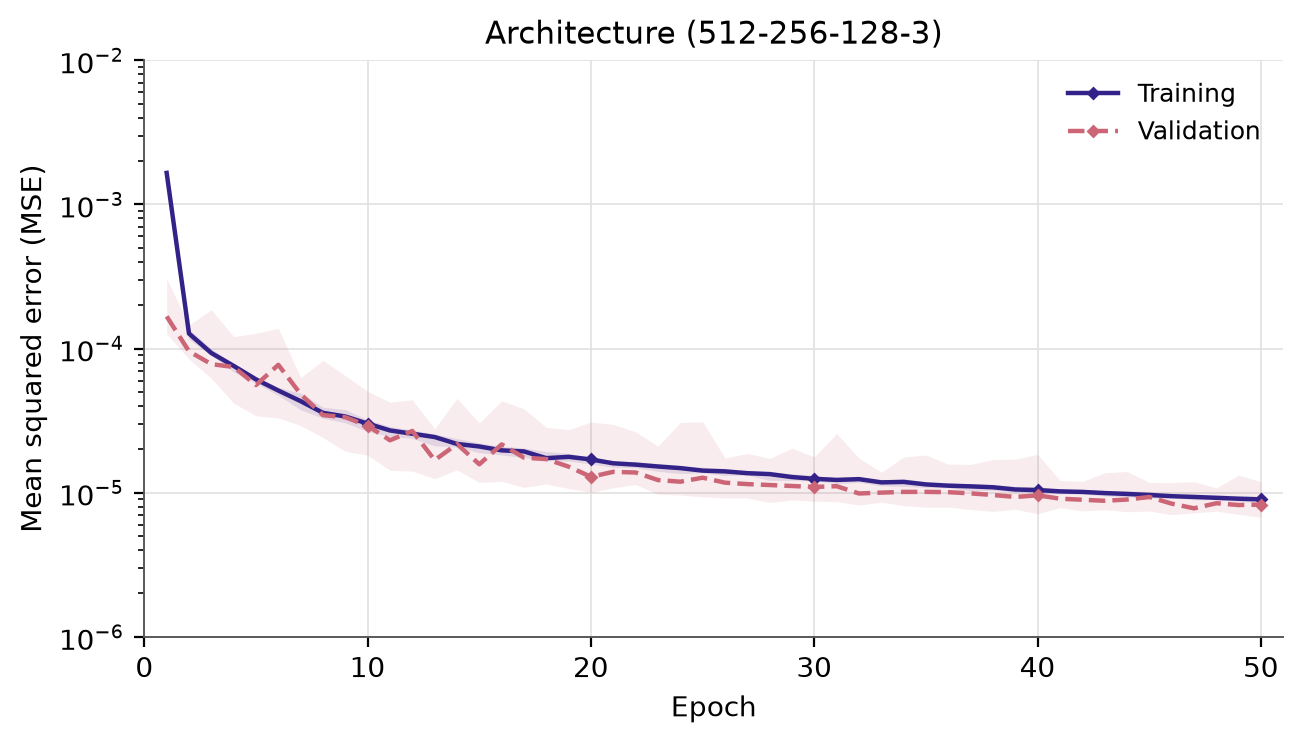

In [11]:
# Evaluate the three-hidden-layer network
train_architecture(ARCHITECTURES[0])
show_learning_curve(ARCHITECTURES[0], "training")

## Model Evaluation

### Target-Family Test Results

The fixed architecture is evaluated on the entire target family after training and validation on source-family rows.

In [12]:
# Summarize test scores for the fixed architecture
selected_architecture = ARCHITECTURES[0]
y_final = test_predictions[selected_architecture]
means = metrics[selected_architecture].mean()
test_summary = pd.DataFrame(
    [[means[f"{target}_{key}"] for target in TARGETS] for key in ["rmse", "r2"]],
    index=pd.Index(["RMSE", "R²"], name="Metric"),
    columns=TARGETS,
)
print(
    f"Architecture {architecture(selected_architecture)} was evaluated on all "
    f"{len(y_test):,} rows in the {TEST_FAMILY} target dataset."
)
print(f"The table reports mean RMSE and R² across {N_RUNS} seeded runs.")
show_table(test_summary)

Architecture (512-256-128-3) was evaluated on all 176,400 rows in the NACA4D_10 target dataset.
The table reports mean RMSE and R² across 20 seeded runs.


,CL,CD,Cm
Metric,,,
RMSE,0.023781,0.005702,0.011062
R²,0.999258,0.724293,0.988522


### Target vs Predicted Coefficients

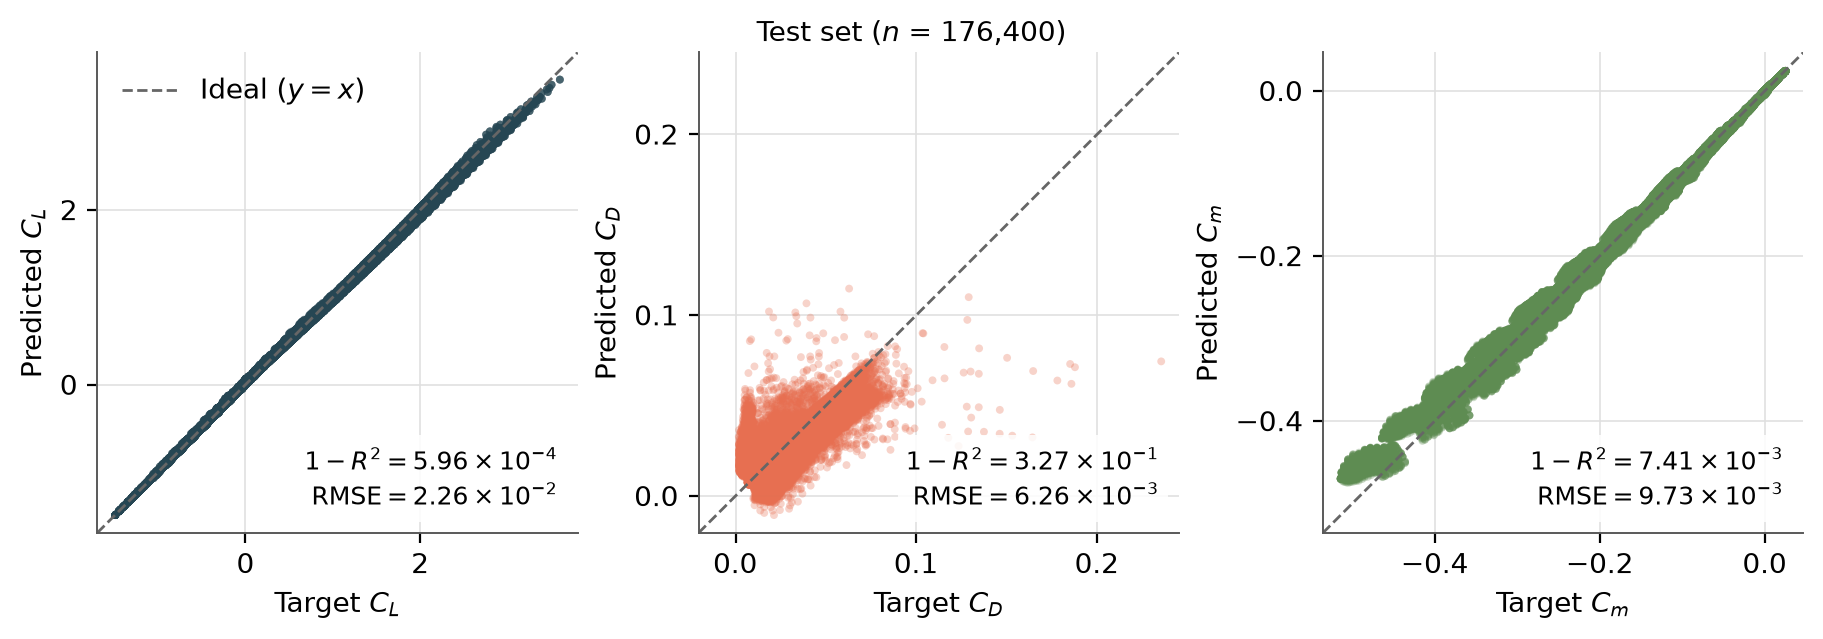

In [13]:
# Compare actual and predicted coefficients for the fixed-seed run
def scientific_notation(value):
    if value == 0:
        return "0"
    mantissa, exponent = f"{value:.2e}".split("e")
    return rf"{mantissa} \times 10^{{{int(exponent)}}}"


actual = np.asarray(y_test)
parity_rmse = np.sqrt(mean_squared_error(actual, y_final, multioutput="raw_values"))
parity_r2 = r2_score(actual, y_final, multioutput="raw_values")
fig, axes = plt.subplots(1, 3, figsize=(9, 3.1))
for j, (ax, target, color) in enumerate(
    zip(axes, [r"$C_L$", r"$C_D$", r"$C_m$"], ["#264653", "#E76F51", "#5E8C52"])
):
    low = min(actual[:, j].min(), y_final[:, j].min())
    high = max(actual[:, j].max(), y_final[:, j].max())
    pad = max((high - low) * 0.04, 1e-6)
    locator = MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10])
    ticks = locator.tick_values(low - pad, high + pad)
    limits = (low - pad, high + pad)
    ticks = ticks[(ticks >= limits[0]) & (ticks <= limits[1])]
    ax.plot(
        limits,
        limits,
        color="0.4",
        linestyle="--",
        linewidth=1,
        label=r"Ideal ($y = x$)",
    )
    ax.scatter(
        actual[:, j],
        y_final[:, j],
        s=8,
        marker="o",
        color=color,
        alpha=0.3,
        edgecolors="none",
        linewidths=0,
    )
    ax.set(
        xlabel=f"Target {target}",
        ylabel=f"Predicted {target}",
        xlim=limits,
        ylim=limits,
    )
    ax.text(
        0.96,
        0.04,
        rf"$1 - R^2 = {scientific_notation(1 - parity_r2[j])}$"
        "\n"
        rf"$\mathrm{{RMSE}} = {scientific_notation(parity_rmse[j])}$",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 3},
    )
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.ticklabel_format(axis="both", style="sci", scilimits=(-3, 4))
    ax.set_aspect("equal", adjustable="box")
    ax.grid(axis="both", which="major", color="0.88", linewidth=0.6)
axes[0].legend(fontsize=10)
fig.align_ylabels()
fig.text(
    0.5, 0.98, f"Test set ($n$ = {len(actual):,})", ha="center", va="top", fontsize=10
)
fig.get_layout_engine().set(rect=(0, 0, 1, 0.96))
finish_figure(
    fig,
    "held-out-parity",
    caption=f"Test set (n = {len(actual):,}). Target and predicted coefficients for architecture "
    f"{architecture(selected_architecture)}. Seed 42 is fixed in advance and is not "
    "selected by validation or test performance. Panel metrics (1 − R² and RMSE) are computed "
    "from the plotted test predictions in the original coefficient scale, not averaged "
    "across training runs. The dashed line shows ideal agreement.",
)

## Results Export

In [14]:
# Save per-seed metrics and dataset row identifiers
experiment_results.export_results(
    ROOT,
    NOTEBOOK_NAME,
    DATASETS,
    {"train": X_train.index, "validation": X_val.index, "test": X_test.index},
    metrics,
    validation_metrics,
    histories,
    experiment_results.training_settings(N_RUNS, EPOCHS, y_train, "cross-family"),
)